# Controle sintético: o imposto sobre o cigarro na Califórnia reduziu o consumo?

**Contexto:** em novembro de 1988 a Califórnia aprovou a *Proposition 99*: imposto de 25 centavos por maço e verba para campanhas antitabagismo. O consumo caiu nos anos seguintes. A pergunta causal é: **quanto dessa queda foi a lei**, e quanto teria acontecido de qualquer jeito?

**Por que é difícil:** só um estado foi tratado, não houve sorteio, e o consumo já caía no país inteiro. Comparar antes × depois atribui à lei uma tendência nacional; comparar com a média dos outros estados supõe que eles seriam um bom espelho da Califórnia.

**Método:** controle sintético ([Abadie, Diamond e Hainmueller, 2010](https://economics.mit.edu/sites/default/files/publications/Synthetic%20Control%20Methods.pdf)), implementado do zero em `src/causal/controle_sintetico.py`. A validade é testada com placebos no espaço, no tempo e retirando um doador por vez.

**Dados:** vendas anuais de cigarro per capita (maços) em 39 estados americanos, 1970–2000. São os estados sem programas antitabagismo parecidos no período. Base usada no artigo original, obtida do repositório público de [Matheus Facure](https://github.com/matheusfacure/python-causality-handbook) (licença MIT).

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from causal.controle_sintetico import (controle_sintetico, diferenca_em_diferencas, p_valor_permutacao,
                                       placebos_no_espaco)
from causal.estilo import COR, aplicar, br, fonte, subtitulo

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: Abadie, Diamond e Hainmueller (2010), via Facure · elaboração: Cézar Bento"
FIG = "../figures/"

dados = pd.read_csv("../data/prop99_cigarros.csv")
painel = dados.pivot(index="year", columns="state", values="cigsale")  # anos × estados
CA = dados.loc[dados.california, "state"].iloc[0]
INICIO = 1989  # primeiro ano inteiro com a lei
print(f"{painel.shape[1]} estados · {painel.index.min()}–{painel.index.max()} · Califórnia = estado {CA}")
print(f"Califórnia: {br(painel.loc[1988, CA], 1)} maços per capita em 1988 → {br(painel.loc[2000, CA], 1)} em 2000")

39 estados · 1970–2000 · Califórnia = estado 3
Califórnia: 90,1 maços per capita em 1988 → 41,6 em 2000


## 1. Por que as comparações simples enganam

Tendência 1970–1988: Califórnia -1,78 maços/ano · outros estados -0,55 maços/ano
Diferença Califórnia − outros: 2,9 em 1970 → -23,7 em 1988


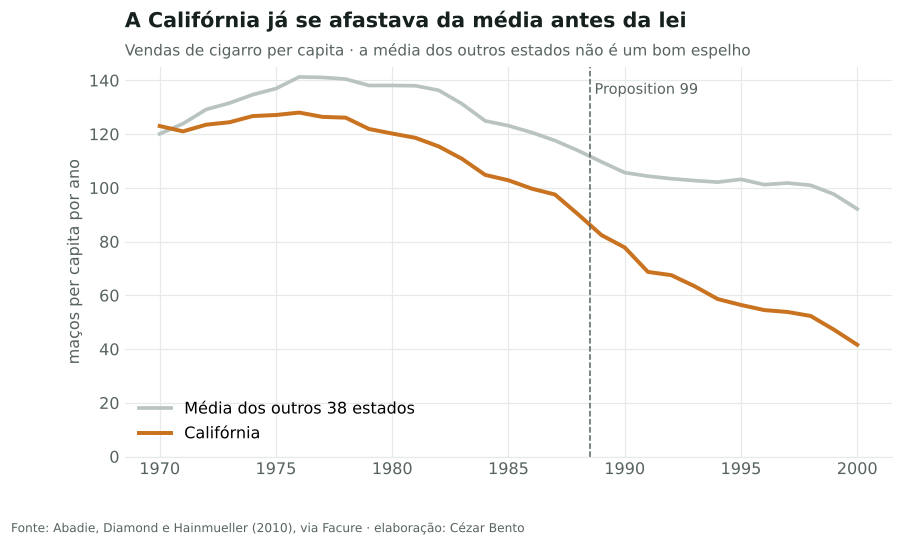

In [2]:
outros = painel.drop(columns=CA).mean(axis=1)
antes = painel.index < INICIO
inclinacao = lambda s: np.polyfit(s.index[s.index < INICIO], s[s.index < INICIO], 1)[0]
print(f"Tendência 1970–1988: Califórnia {br(inclinacao(painel[CA]), 2)} maços/ano · outros estados {br(inclinacao(outros), 2)} maços/ano")
print(f"Diferença Califórnia − outros: {br(painel.loc[1970, CA] - outros.loc[1970], 1)} em 1970 → {br(painel.loc[1988, CA] - outros.loc[1988], 1)} em 1988")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(painel.index, outros, color=COR["contexto"], lw=2.4, label="Média dos outros 38 estados")
ax.plot(painel.index, painel[CA], color=COR["destaque"], lw=2.6, label="Califórnia")
ax.axvline(INICIO - 0.5, color=COR["texto2"], lw=1, ls="--")
ax.text(INICIO - 0.3, 135, "Proposition 99", fontsize=9.5, color=COR["texto2"])
ax.set_ylabel("maços per capita por ano"); ax.legend(loc="lower left"); ax.set_ylim(0, 145)
ax.set_title("A Califórnia já se afastava da média antes da lei")
subtitulo(ax, "Vendas de cigarro per capita · a média dos outros estados não é um bom espelho")
fonte(fig, FONTE)
fig.savefig(FIG + "06_california_vs_media.png")

A Califórnia partiu do mesmo nível da média em 1970, mas caía três vezes mais rápido **antes** da lei. A diferença-em-diferenças com a média dos outros estados supõe tendências paralelas, e essa suposição não vale aqui. O controle sintético busca uma combinação de estados que tenha acompanhado a Califórnia de perto entre 1970 e 1988.

## 2. O controle sintético

In [3]:
res = controle_sintetico(painel, CA, INICIO)
pesos = res.pesos[res.pesos > 0.005].sort_values(ascending=False)
print("Pesos dos estados doadores:"); print((pesos * 100).round(1).astype(str).add("%").to_string())
print(f"\nErro de ajuste antes da lei (RMSPE): {br(res.rmspe(False), 2)} maços")
efeito = res.efeito
for ano in [1989, 1995, 2000]:
    print(f"{ano}: real {br(res.real[ano], 1)} · sintético {br(res.sintetico[ano], 1)} · efeito {br(efeito[ano], 1)} maços")
print(f"Efeito médio 1989–2000: {br(efeito.loc[INICIO:].mean(), 1)} maços per capita por ano")
print(f"Em 2000, o consumo foi {br(-efeito[2000] / res.sintetico[2000] * 100)}% menor do que seria sem a lei")

Pesos dos estados doadores:
34    39.4%
19    23.2%
21    20.5%
5     10.9%
22     4.5%
4      1.5%

Erro de ajuste antes da lei (RMSPE): 1,66 maços
1989: real 82,4 · sintético 90,8 · efeito -8,4 maços
1995: real 56,4 · sintético 79,3 · efeito -22,9 maços
2000: real 41,6 · sintético 68,2 · efeito -26,6 maços
Efeito médio 1989–2000: -19,5 maços per capita por ano
Em 2000, o consumo foi 39% menor do que seria sem a lei


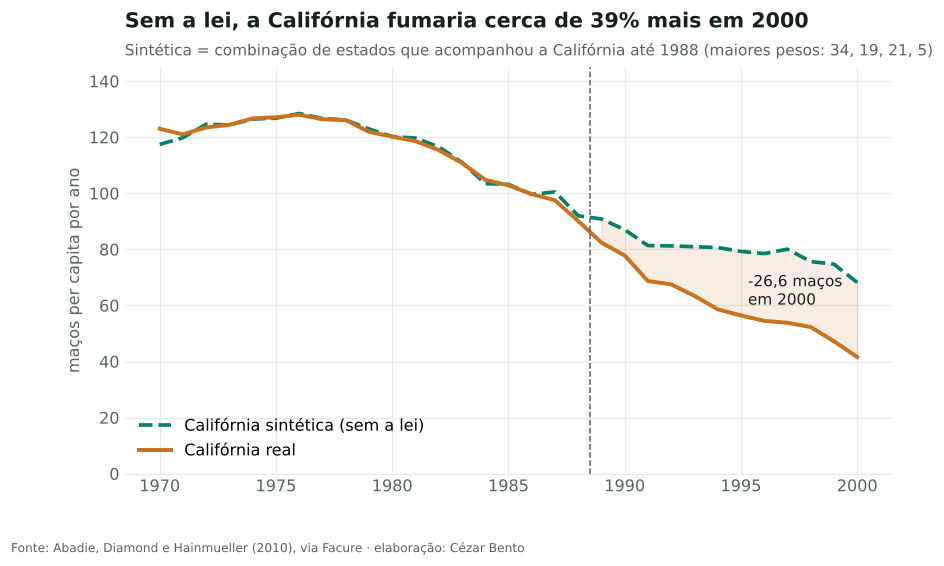

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(painel.index, res.sintetico, color=COR["principal"], lw=2.4, ls="--", label="Califórnia sintética (sem a lei)")
ax.plot(painel.index, res.real, color=COR["destaque"], lw=2.6, label="Califórnia real")
depois = painel.index >= INICIO
ax.fill_between(painel.index[depois], res.real[depois], res.sintetico[depois], color=COR["destaque"], alpha=0.12)
ax.axvline(INICIO - 0.5, color=COR["texto2"], lw=1, ls="--")
ax.text(1995.3, 65, f"{br(efeito[2000], 1)} maços\nem 2000", fontsize=10, color=COR["texto"], va="center")
ax.set_ylabel("maços per capita por ano"); ax.set_ylim(0, 145); ax.legend(loc="lower left")
ax.set_title(f"Sem a lei, a Califórnia fumaria cerca de {br(-efeito[2000] / res.sintetico[2000] * 100)}% mais em 2000")
estados = ", ".join(str(e) for e in pesos.head(4).index)
subtitulo(ax, f"Sintética = combinação de estados que acompanhou a Califórnia até 1988 (maiores pesos: {estados})")
fonte(fig, FONTE)
fig.savefig(FIG + "07_controle_sintetico.png")

## 3. O efeito é real ou poderia ser acaso? Placebos no espaço

Repito o método fingindo que **cada um dos outros 38 estados** recebeu a lei em 1989. Se a Califórnia for só mais um estado com um desvio qualquer, o efeito dela vai se parecer com esses efeitos de mentira.

A estatística de comparação é a razão entre o erro **depois** e o erro **antes** da lei. Ela pune estados que o método não consegue imitar bem, porque um desvio grande depois não significa nada se o ajuste antes já era ruim.

In [5]:
placebos = placebos_no_espaco(painel, CA, INICIO)
p = p_valor_permutacao(placebos)
ordem = placebos["razao"].rank(ascending=False).astype(int)
print(f"Posição da Califórnia pela razão depois/antes: {ordem[CA]}º de {len(placebos)} → p-valor de permutação = {p:.3f}")
print(f"Posição pelo tamanho do desvio depois da lei: {int(placebos['rmspe_depois'].rank(ascending=False)[CA])}º de {len(placebos)}")
print("\nEstados com razão maior ou igual à da Califórnia:")
print(placebos.sort_values("razao", ascending=False).head(ordem[CA])[["rmspe_antes", "rmspe_depois", "razao"]].round(2).to_string())

Posição da Califórnia pela razão depois/antes: 3º de 39 → p-valor de permutação = 0.077
Posição pelo tamanho do desvio depois da lei: 3º de 39

Estados com razão maior ou igual à da Califórnia:
         rmspe_antes  rmspe_depois  razao
unidade                                  
18              0.44         10.47  23.92
36              0.82         16.18  19.83
3               1.66         20.61  12.44


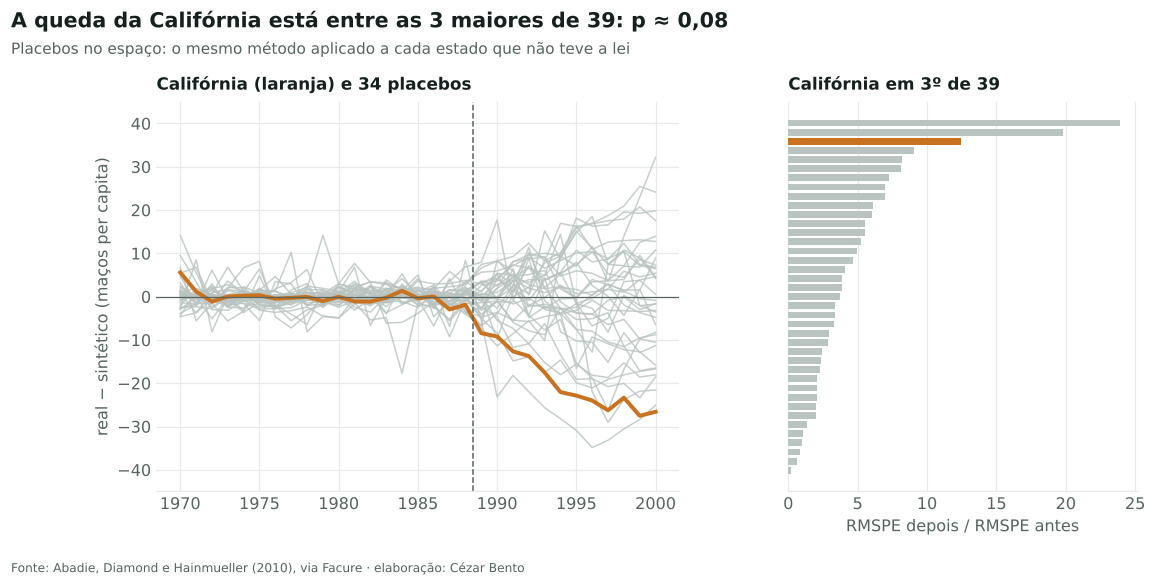

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.25})
ax = axes[0]
# Como no artigo original, só entram no gráfico os placebos com ajuste razoável antes da lei
bons = placebos[placebos.rmspe_antes <= 5 * placebos.loc[CA, "rmspe_antes"]]
for unidade, linha in bons.iterrows():
    if unidade != CA:
        ax.plot(linha.efeito.index, linha.efeito.values, color=COR["contexto"], lw=1, alpha=0.8)
ax.plot(efeito.index, efeito.values, color=COR["destaque"], lw=2.6)
ax.axhline(0, color=COR["texto2"], lw=0.8); ax.axvline(INICIO - 0.5, color=COR["texto2"], lw=1, ls="--")
ax.set_ylabel("real − sintético (maços per capita)"); ax.set_ylim(-45, 45)
ax.set_title(f"Califórnia (laranja) e {len(bons) - 1} placebos", fontsize=11, pad=8)

ax = axes[1]
razoes = placebos["razao"].sort_values()
cores = [COR["destaque"] if u == CA else COR["contexto"] for u in razoes.index]
ax.barh(range(len(razoes)), razoes.values, color=cores, height=0.75)
ax.set_yticks([]); ax.set_xlabel("RMSPE depois / RMSPE antes"); ax.grid(axis="y", visible=False)
ax.set_title(f"Califórnia em {ordem[CA]}º de {len(placebos)}", fontsize=11, pad=8)
fig.suptitle(f"A queda da Califórnia está entre as 3 maiores de 39: p ≈ {br(p, 2)}",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", color=COR["texto"], y=1.06)
fig.text(0.01, 0.975, "Placebos no espaço: o mesmo método aplicado a cada estado que não teve a lei",
         fontsize=10, color=COR["texto2"])
fonte(fig, FONTE, y=-0.03)
fig.savefig(FIG + "08_placebos_espaco.png")

**Leitura honesta:** a Califórnia tem um dos maiores desvios entre os 39 estados, mas não o maior. Dois estados com ajuste muito bom antes de 1989 também se afastam dos seus sintéticos depois. O p-valor de permutação fica perto de 0,08: **evidência moderada**, não conclusiva, nesta versão simplificada do método.

O artigo original chega a p ≈ 0,03 porque ajusta os pesos também por covariáveis (renda, preço do cigarro, consumo de cerveja, proporção de jovens). Isso melhora o ajuste da Califórnia, que é um estado atípico. Aqui deixei de fora as covariáveis porque metade delas tem valores ausentes nesta base. O ponto a registrar é que **a conclusão depende dessa escolha**, e isso precisa ir para o relatório.

## 4. Robustez: o resultado depende de um doador? E de quando a lei começou?

In [7]:
# Tirar um doador por vez: se o efeito dependesse de um único estado, ele mudaria muito
sem_um = {}
for doador in pesos.index:
    r = controle_sintetico(painel, CA, INICIO, [c for c in painel.columns if c not in (CA, doador)])
    sem_um[doador] = r
    print(f"Sem o estado {doador:>2}: efeito em 2000 = {br(r.efeito[2000], 1)} · médio = {br(r.efeito.loc[INICIO:].mean(), 1)} · "
          f"ajuste antes = {br(r.rmspe(False), 2)}")

# Placebo no tempo: fingir que a lei começou em 1985, usando só dados até 1988
falso = controle_sintetico(painel.loc[:1988], CA, 1985, fim_ajuste=1984)
print("\nPlacebo no tempo (lei fictícia em 1985):", ", ".join(f"{a}: {br(v, 1)}" for a, v in falso.efeito.loc[1985:1988].items()))

Sem o estado 34: efeito em 2000 = -25,4 · médio = -19,1 · ajuste antes = 2,38
Sem o estado 19: efeito em 2000 = -24,9 · médio = -18,0 · ajuste antes = 1,76
Sem o estado 21: efeito em 2000 = -27,0 · médio = -19,2 · ajuste antes = 2,22
Sem o estado  5: efeito em 2000 = -28,4 · médio = -20,5 · ajuste antes = 1,81
Sem o estado 22: efeito em 2000 = -26,7 · médio = -19,8 · ajuste antes = 1,70
Sem o estado  4: efeito em 2000 = -26,7 · médio = -19,6 · ajuste antes = 1,66

Placebo no tempo (lei fictícia em 1985): 1985: -3,3, 1986: -3,9, 1987: -8,6, 1988: -8,7


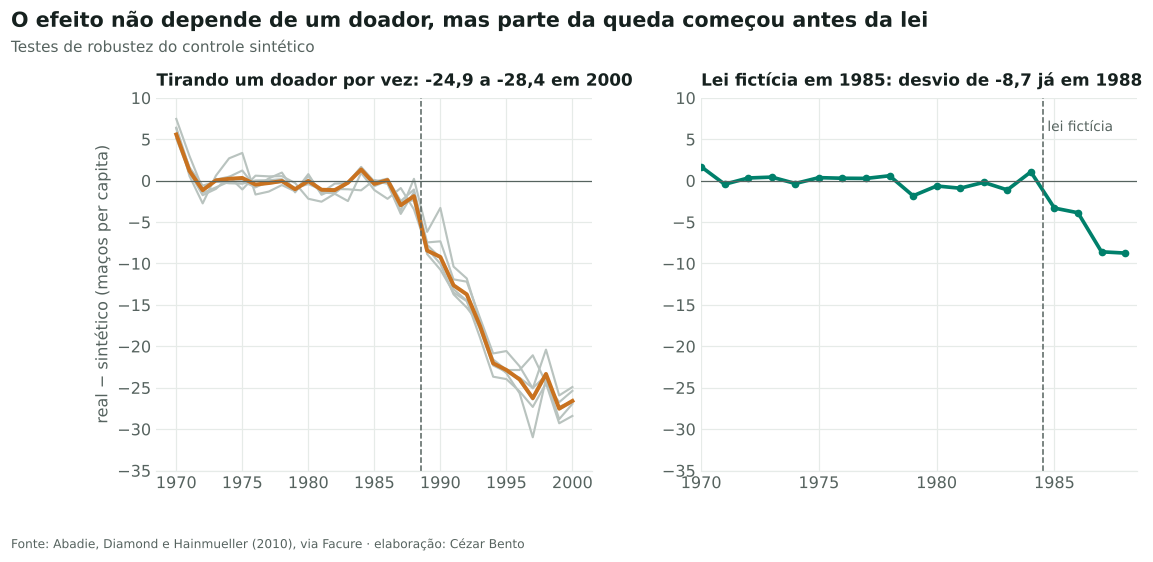

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"wspace": 0.25})
ax = axes[0]
for doador, r in sem_um.items():
    ax.plot(r.efeito.index, r.efeito.values, color=COR["contexto"], lw=1.4)
ax.plot(efeito.index, efeito.values, color=COR["destaque"], lw=2.6)
ax.axhline(0, color=COR["texto2"], lw=0.8); ax.axvline(INICIO - 0.5, color=COR["texto2"], lw=1, ls="--")
faixa = [r.efeito[2000] for r in sem_um.values()]
ax.set_title(f"Tirando um doador por vez: {br(max(faixa), 1)} a {br(min(faixa), 1)} em 2000", fontsize=11, pad=8)
ax.set_ylabel("real − sintético (maços per capita)"); ax.set_ylim(-35, 10)

ax = axes[1]
ax.plot(falso.efeito.index, falso.efeito.values, color=COR["principal"], lw=2.4, marker="o", ms=4)
ax.axhline(0, color=COR["texto2"], lw=0.8); ax.axvline(1984.5, color=COR["texto2"], lw=1, ls="--")
ax.text(1984.7, 6, "lei fictícia", fontsize=9, color=COR["texto2"])
ax.set_ylim(-35, 10); ax.set_xlim(1970, 1988.5); ax.set_xticks(range(1970, 1989, 5))
ax.set_title(f"Lei fictícia em 1985: desvio de {br(falso.efeito[1988], 1)} já em 1988", fontsize=11, pad=8)
fig.suptitle("O efeito não depende de um doador, mas parte da queda começou antes da lei",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", color=COR["texto"], y=1.06)
fig.text(0.01, 0.975, "Testes de robustez do controle sintético", fontsize=10, color=COR["texto2"])
fonte(fig, FONTE, y=-0.03)
fig.savefig(FIG + "09_robustez.png")

**Leitura:** retirar qualquer doador muda pouco o efeito, então ele não é obra de um único estado. Mas o placebo no tempo mostra um desvio de cerca de 9 maços em 1987–1988, **antes** da lei valer. Pode ser antecipação (a campanha da Proposition 99 aconteceu em 1988, e os fabricantes subiram preços) ou uma tendência própria da Califórnia que o método não captura. Nos dois casos, uma leitura conservadora desconta esse desvio.

## 5. Comparando os métodos

In [9]:
estimativas = pd.Series({
    "Antes × depois (só Califórnia)": painel.loc[INICIO:, CA].mean() - painel.loc[:INICIO - 1, CA].mean(),
    "Diferença-em-diferenças (média dos estados)": diferenca_em_diferencas(painel, CA, INICIO),
    "Controle sintético": efeito.loc[INICIO:].mean(),
    "Controle sintético, descontado o desvio pré-lei": efeito.loc[INICIO:].mean() - falso.efeito[1988],
})
print("Efeito médio 1989–2000 (maços per capita por ano):")
print(estimativas.round(1).to_string())

Efeito médio 1989–2000 (maços per capita por ano):
Antes × depois (só Califórnia)                    -55.9
Diferença-em-diferenças (média dos estados)       -27.3
Controle sintético                                -19.5
Controle sintético, descontado o desvio pré-lei   -10.8


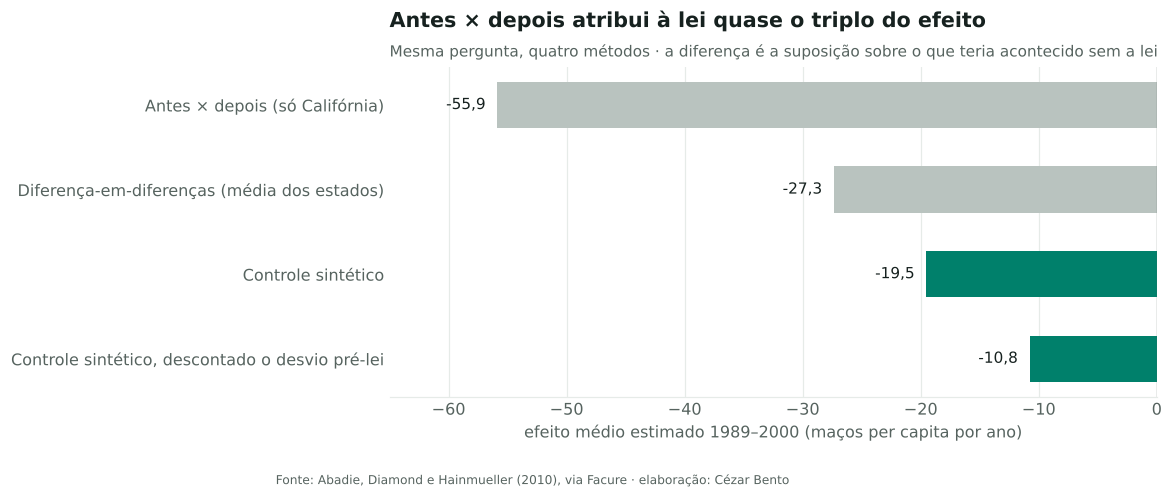

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.9))
cores = [COR["contexto"], COR["contexto"], COR["principal"], COR["principal"]]
ax.barh(estimativas.index[::-1], estimativas.values[::-1], color=cores[::-1], height=0.55)
for i, v in enumerate(estimativas.values[::-1]):
    ax.text(v - 1, i, br(v, 1), va="center", ha="right", fontsize=10, color=COR["texto"])
ax.axvline(0, color=COR["texto2"], lw=0.8); ax.set_xlim(-65, 0); ax.grid(axis="y", visible=False)
ax.set_xlabel("efeito médio estimado 1989–2000 (maços per capita por ano)")
ax.set_title("Antes × depois atribui à lei quase o triplo do efeito")
subtitulo(ax, "Mesma pergunta, quatro métodos · a diferença é a suposição sobre o que teria acontecido sem a lei")
fonte(fig, FONTE, y=-0.07)
fig.savefig(FIG + "10_metodos.png")

## Conclusão

- **Efeito estimado:** a lei reduziu o consumo em cerca de **20 maços per capita por ano** no período 1989–2000, chegando a **27 maços em 2000** (cerca de 40% abaixo do contrafactual). Descontado o desvio que já aparecia antes da lei, o efeito médio fica perto de **11 maços**.
- **Robustez:** o resultado não depende de nenhum estado doador isolado.
- **Incerteza:** no teste de permutação, a Califórnia fica entre as 3 maiores quedas de 39 (p ≈ 0,08). É uma evidência de efeito, mas não uma prova, nesta especificação.
- **Lição de método:** antes × depois atribuiria à lei quase 3 vezes o efeito, porque o consumo caía no país inteiro. A escolha do contrafactual é a decisão mais importante da análise.

**Como isso aparece no trabalho:** a mesma pergunta surge quando uma empresa muda o preço numa região, abre uma loja ou lança uma campanha numa cidade. Não há sorteio, só uma unidade tratada e muitas candidatas a controle. O controle sintético dá um contrafactual explícito e auditável, e os placebos mostram quanto confiar nele.